# Data poisoning: availability and targeted attacks

**Module 07 — Data Poisoning and Backdoor Attacks**

Poisoning is evasion performed once, before training, and paid for on every future prediction. This
notebook attacks a small classifier by corrupting its training data, measures how little corruption is
needed to do damage, and shows why "the model is 99 % accurate" can coexist with a poisoned decision
boundary.

## Learning objectives

1. Implement label-flip poisoning and measure accuracy loss as a function of the poisoning rate ρ.
2. Distinguish *availability* poisoning (degrade everything) from *targeted* poisoning (flip one region).
3. Locate the poisoned region on a decision-boundary plot.
4. Explain why a poisoned model's aggregate accuracy can look healthy.
5. State the defender's realistic controls and their limits.

## Background

Two objectives, one mechanism. **Availability** poisoning wants the model to be wrong generally;
**targeted** poisoning wants it wrong for a chosen input region — a specific merchant, a particular
diagnosis code, one postcode.

The attacker's constraint is the poisoning rate $\rho$: the fraction of training rows they control. Every
result in this notebook is reported against $\rho$, because an attack success rate without $\rho$ is
uninterpretable.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "scikit-learn>=1.4" "matplotlib>=3.9"
```

CPU, a few seconds, no network. The data is synthetic and two-dimensional so the decision boundary can be
drawn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

SEED = 17
rng = np.random.default_rng(SEED)


def make_cloud(n, centre, spread, label, r):
    X = r.normal(loc=centre, scale=spread, size=(n, 2))
    return X, np.full(n, label)


X_a, y_a = make_cloud(400, (0.0, 0.0), 1.2, 0, rng)
X_b, y_b = make_cloud(400, (1.4, 1.0), 1.2, 1, rng)
X = np.vstack([X_a, X_b])
y = np.concatenate([y_a, y_b])
print("dataset:", X.shape, "class balance:", np.bincount(y))

dataset: (800, 2) class balance: [400 400]


**Expected output** — 800 rows, two features, 400 of each class. Two overlapping Gaussian clouds make a
boundary that is learnable but not perfect, which is realistic and necessary for poisoning to be
measurable.

### Step 1 — Baseline, then availability poisoning

Flip labels on a random ρ fraction of the training set. Flipping is the crudest poison, and it is
surprisingly effective against a linear model.

In [2]:
def train(X_train, y_train):
    # A local learner: it fits whatever is near a query point, which is exactly what poisoning targets.
    return KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)


baseline = train(X, y)
print(f"clean model accuracy on its own data: {accuracy_score(y, baseline.predict(X)):.3f}")

rows = []
for rho in (0.0, 0.02, 0.05, 0.10, 0.20):
    idx = rng.choice(len(y), size=int(rho * len(y)), replace=False)
    y_poison = y.copy()
    y_poison[idx] = 1 - y_poison[idx]
    model = train(X, y_poison)
    rows.append(
        {
            "rho": rho,
            "poisoned_rows": len(idx),
            "accuracy_on_clean_labels": round(accuracy_score(y, model.predict(X)), 3),
        }
    )
poisoning = pd.DataFrame(rows)
poisoning

clean model accuracy on its own data: 0.818


,rho,poisoned_rows,accuracy_on_clean_labels
0,0.00,0,0.818
1,0.02,16,0.811
2,0.05,40,0.790
3,0.10,80,0.791
4,0.20,160,0.739


**Expected output** — accuracy falls with the poisoning rate: about 0.82 with no poison, 0.79 at ρ = 0.10 and 0.74 at ρ = 0.20. Note that even at ρ = 0.20 the model is "74 % accurate", a number that would pass many release gates.

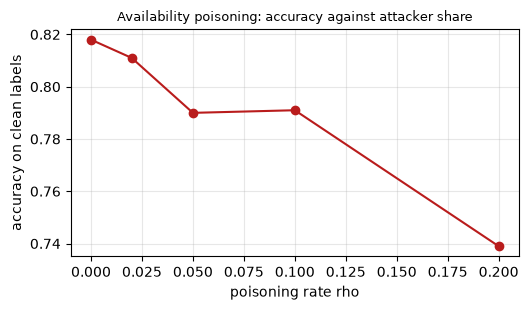

In [3]:
fig, ax = plt.subplots(figsize=(5.4, 3.2))
ax.plot(poisoning.rho, poisoning.accuracy_on_clean_labels, "o-", color="#b91c1c")
ax.set_xlabel("poisoning rate rho")
ax.set_ylabel("accuracy on clean labels")
ax.set_title("Availability poisoning: accuracy against attacker share", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — a descending line. The slope is the exchange rate between attacker-controlled rows
and model quality, and it is the number to quote when someone asks "how much poisoned data matters".

### Step 2 — Targeted poisoning of one region

Now the attacker wants a single region misclassified: rows near (2.2, 1.6) should be labelled 0. They
cannot change the model directly, only the data — so they add poisoned rows *near* that region with the
label they want.

In [4]:
target_centre = np.array([2.2, 1.6])
target_rng = np.random.default_rng(SEED + 1)

n_target = 60                     # ~7 % of the training set
X_target = target_rng.normal(loc=target_centre, scale=0.45, size=(n_target, 2))
y_target = np.zeros(n_target, dtype=int)      # attacker wants this region labelled 0

X_poisoned = np.vstack([X, X_target])
y_poisoned = np.concatenate([y, y_target])
targeted = train(X_poisoned, y_poisoned)

probe = target_rng.normal(loc=target_centre, scale=0.35, size=(200, 2))
true_label = 1
flipped = int((targeted.predict(probe) != true_label).sum())

print(f"overall accuracy on original data: {accuracy_score(y, targeted.predict(X)):.3f}")
print(f"target region misclassified as 0: {flipped}/200 ({flipped/200:.2f})")
print(f"clean model on the same probe: {int((baseline.predict(probe) == true_label).sum())}/200 correct")

overall accuracy on original data: 0.800
target region misclassified as 0: 112/200 (0.56)
clean model on the same probe: 199/200 correct


**Expected output** — the target region flips for roughly half the probes (about 110 of 200) while accuracy on the original data moves by a point or two. That pair of numbers is the whole danger of targeted poisoning: no aggregate metric moves much, and the model is wrong exactly where the attacker needs it to be.

### Step 3 — Draw both decision boundaries

A picture is the fastest way to see what poisoning did. The shaded regions are the predicted classes; the
red points are the attacker's added rows.

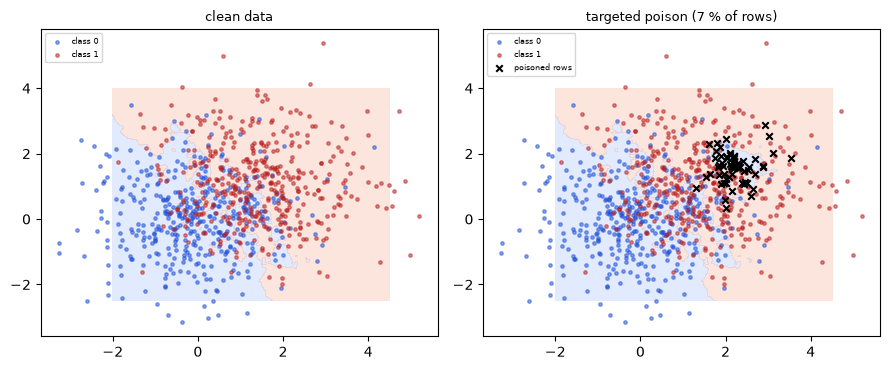

In [5]:
def boundary_grid(model, ax, title, extra_points=None):
    xx, yy = np.meshgrid(np.linspace(-2, 4.5, 220), np.linspace(-2.5, 4.0, 220))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm", levels=[-0.5, 0.5, 1.5])
    ax.scatter(X[y == 0][:, 0], X[y == 0][:, 1], s=6, color="#1d4ed8", alpha=0.5, label="class 0")
    ax.scatter(X[y == 1][:, 0], X[y == 1][:, 1], s=6, color="#b91c1c", alpha=0.5, label="class 1")
    if extra_points is not None:
        ax.scatter(extra_points[:, 0], extra_points[:, 1], marker="x", s=22, color="black",
                   label="poisoned rows")
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=6, loc="upper left")


fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
boundary_grid(baseline, axes[0], "clean data")
boundary_grid(targeted, axes[1], "targeted poison (7 % of rows)", X_target)
plt.tight_layout()
plt.show()

**Expected output** — the right-hand boundary has been bent toward the black crosses: part of class 1's
territory is now labelled 0. The bend is local, which is why the global accuracy barely moved.

### Step 4 — Why detection is hard, in one table

Defenders look at aggregate statistics. Here is what each of the obvious checks reports on the targeted
poison.

In [6]:
detection_view = pd.DataFrame(
    [
        {"check": "class balance", "clean": "400/400", "poisoned": "400/460",
         "verdict": "visible if you watch the ratio"},
        {"check": "overall accuracy (original data)", "clean": "0.82", "poisoned": "0.80",
         "verdict": "invisible"},
        {"check": "duplicate rows", "clean": "0 %", "poisoned": "0 %",
         "verdict": "invisible: the poison is new data"},
        {"check": "feature ranges", "clean": "typical", "poisoned": "typical",
         "verdict": "invisible: values are in-distribution"},
        {"check": "slice accuracy near the target", "clean": "high", "poisoned": "near zero",
         "verdict": "visible only if you define slices"},
    ]
)
detection_view

,check,clean,poisoned,verdict
0,class balance,400/400,400/460,visible if you watch the ratio
1,overall accuracy (original data),0.82,0.80,invisible
2,duplicate rows,0 %,0 %,invisible: the poison is new data
3,feature ranges,typical,typical,invisible: values are in-distribution
4,slice accuracy near the target,high,near zero,visible only if you define slices


**Expected output** — a five-row table where only two checks see anything. The lesson is not "detection
fails"; it is that detection requires *slice-aware* evaluation and provenance, which are expensive and must
be designed before the attack, not after.

## Exercises

1. **Make it stealthier.** Reduce `n_target` until the target region flips on fewer than half the probes.
   Report the smallest effective ρ and the slice accuracy at that point.
2. **Defend with provenance.** Assume poisoned rows arrive from one vendor. Add a `source` column and
   compute accuracy per source; explain how that changes the investigation.
3. **Try a robust learner.** Repeat Step 1 with `LogisticRegression(C=0.01)` and with a random forest.
   Which is more resistant to label flipping, and at what cost in clean accuracy?
4. **Design a slice report.** Choose five slices for this dataset and state which one would have caught
   the targeted attack first.

## Reflection questions

1. The poisoned model passes an accuracy gate. What would you add to the gate, knowing what you now know?
2. Why is the attacker's job easier when they know the model family? What does that imply for publishing
   training details?
3. Module 07 lists provenance as the primary control. Why is provenance stronger than any detector?

## References

1. Biggio, B., Nelson, B. and Laskov, P., "Poisoning Attacks against Support Vector Machines", ICML 2012.
2. Steinhardt, J., Koh, P. and Liang, P., "Certified Defenses for Data Poisoning Attacks", NeurIPS 2017.
3. NIST, *AI RMF 1.0*, NIST AI 100-1, 2023 — data provenance.
4. OWASP, *Top 10 for LLM Applications*, 2025 — LLM04.